# 📈 FloodShield AI — Model 3: Time Series Forecasting (LSTM)
**Algorithm:** LSTM (TensorFlow/Keras)
**Predict:** Next 7 Days & Next 14 Days disease case count (district-wise)
**Dataset:** `disease_prediction_dataset_fixed.xlsx`

### ⚠️ গুরুত্বপূর্ণ Data Note (আগে পড়ে নাও)
এই dataset-এ প্রতিদিনের continuous case count নেই — প্রতিটা row একটা "snapshot" (previous_week_cases → future_cases), আর dates অনিয়মিত ব্যবধানে (0-11+ দিন gap)।

তাই সরাসরি daily LSTM বানানো সম্ভব না। এই notebook করছে:
1. প্রতি district-এর জন্য **weekly aggregate** বানানো (previous_week_cases-কে সেই সপ্তাহের case-count signal ধরে)
2. Missing week interpolate করে একটা **continuous weekly time series** বানানো
3. Sliding window (গত ৮ সপ্তাহ) দিয়ে **পরের ১ সপ্তাহ (7 din) ও ২ সপ্তাহ (14 din)** forecast করা

এটা honest approach — raw dataset-এর সীমাবদ্ধতা মেনে নিয়ে যতটা সম্ভব ভালো time-series signal বের করা।

### কীভাবে চালাবে:
1. Drive-এ `disease_prediction_dataset_fixed.xlsx` upload করো (আগেই করা থাকতে পারে)
2. Runtime → Change runtime type → **GPU** সিলেক্ট করো (LSTM training দ্রুত হবে)
3. Runtime → Run all


## 1️⃣ Setup

In [1]:
!pip install tensorflow scikit-learn pandas openpyxl -q

from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
print("GPU available:", tf.config.list_physical_devices('GPU'))


Mounted at /content/drive
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2️⃣ Load Dataset

In [2]:
import pandas as pd
import numpy as np

DATA_PATH = '/content/drive/MyDrive/FloodShieldAI/data/disease_prediction_dataset_fixed.xlsx'  # <-- path বদলাও

df = pd.read_excel(DATA_PATH)
df['date'] = pd.to_datetime(df['date'])
print("Shape:", df.shape)
df.head()


Shape: (30000, 24)


,date,district,upazila,season,rainfall_mm,temperature_c,humidity_percent,river_level_m,flood_depth_cm,population_density,...,future_cases,outbreak_risk,cholera_cases,diarrhea_cases,typhoid_cases,dengue_cases,hepatitis_a_cases,skin_disease_cases,dominant_disease,age_group_affected
0,2024-07-14,Munshiganj,Gazaria,Monsoon,116.1,34.7,90.3,4.80,38.5,4415,...,756,Critical,300,249,66,53,51,37,Cholera,Children
1,2025-02-19,Bagerhat,Fakirhat,Winter,4.7,22.1,59.6,2.50,2.4,4174,...,605,High,18,156,177,57,77,120,Typhoid,Children
2,2024-03-21,Sirajganj,Belkuchi,Summer,8.1,29.6,72.7,2.30,18.0,4720,...,543,High,73,139,179,26,60,65,Typhoid,Elderly
3,2022-06-29,Bhola,Daulatkhan,Monsoon,283.0,30.9,80.9,7.26,54.0,1971,...,944,Critical,170,387,132,75,99,80,Diarrhea,Adults
4,2023-03-20,Faridpur,Nagarkanda,Summer,23.7,33.6,80.2,1.95,23.8,3836,...,633,High,73,104,166,61,90,139,Typhoid,Children


## 3️⃣ Build Weekly District-wise Time Series
`previous_week_cases`-কে সেই সপ্তাহের case-count signal হিসেবে ধরে district+week level-এ aggregate করছি (একাধিক upazila থাকলে mean নিচ্ছি)।


In [3]:
df['week'] = df['date'].dt.to_period('W').dt.start_time

weekly = df.groupby(['district','week']).agg({
    'previous_week_cases': 'mean',
    'rainfall_mm': 'mean',
    'temperature_c': 'mean',
    'flood_depth_cm': 'mean',
    'sanitation_score': 'mean'
}).reset_index()

weekly = weekly.rename(columns={'previous_week_cases':'weekly_cases'})
print("Weekly records:", weekly.shape)
weekly.head()


Weekly records: (11914, 7)


,district,week,weekly_cases,rainfall_mm,temperature_c,flood_depth_cm,sanitation_score
0,Bagerhat,2021-12-27,135.000000,7.200000,23.000000,0.0000,0.400000
1,Bagerhat,2022-01-10,110.000000,10.500000,20.600000,16.7000,0.710000
2,Bagerhat,2022-01-17,113.500000,13.125000,22.500000,10.5625,0.627500
3,Bagerhat,2022-01-24,136.333333,5.633333,19.833333,5.5000,0.576667
4,Bagerhat,2022-01-31,138.250000,3.950000,21.950000,10.8500,0.502500


## 4️⃣ Fill Missing Weeks (Interpolation) — Per District

In [4]:
def fill_district_series(group):
    full_range = pd.date_range(group['week'].min(), group['week'].max(), freq='W-MON')
    group = group.set_index('week').reindex(full_range)
    group = group.interpolate(method='linear').ffill().bfill()
    group.index.name = 'week'
    return group.reset_index()

filled_list = []
for dist, group in weekly.groupby('district'):
    filled = fill_district_series(group.drop(columns='district'))
    filled['district'] = dist
    filled_list.append(filled)

weekly_filled = pd.concat(filled_list, ignore_index=True)
print("After filling:", weekly_filled.shape)

# keep only districts with enough weeks for sequence modeling (>= 60 weeks)
week_counts = weekly_filled.groupby('district').size()
valid_districts = week_counts[week_counts >= 60].index
weekly_filled = weekly_filled[weekly_filled['district'].isin(valid_districts)]
print("Districts kept:", len(valid_districts), "/", weekly['district'].nunique())


After filling: (13381, 7)
Districts kept: 64 / 64


## 5️⃣ Build Sliding-Window Sequences
**Lookback:** গত ৮ সপ্তাহ | **Forecast:** পরের সপ্তাহ (7 din) + তার পরের সপ্তাহ (14 din)


In [5]:
from sklearn.preprocessing import MinMaxScaler

LOOKBACK = 8
feature_cols = ['weekly_cases','rainfall_mm','temperature_c','flood_depth_cm','sanitation_score']

scalers = {}
X_seq, y_7day, y_14day = [], [], []

for dist, group in weekly_filled.groupby('district'):
    group = group.sort_values('week').reset_index(drop=True)
    values = group[feature_cols].values

    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(values)
    scalers[dist] = scaler

    for i in range(len(scaled) - LOOKBACK - 2):
        X_seq.append(scaled[i:i+LOOKBACK])
        y_7day.append(scaled[i+LOOKBACK][0])      # next week's weekly_cases (scaled)
        y_14day.append(scaled[i+LOOKBACK+1][0])   # week-after-next weekly_cases (scaled)

X_seq = np.array(X_seq)
y_7day = np.array(y_7day)
y_14day = np.array(y_14day)

print("X_seq shape:", X_seq.shape)
print("y_7day shape:", y_7day.shape, "| y_14day shape:", y_14day.shape)


X_seq shape: (12741, 8, 5)
y_7day shape: (12741,) | y_14day shape: (12741,)


## 6️⃣ Train/Test Split (time-respecting, not random shuffle)

In [6]:
split_idx = int(len(X_seq) * 0.85)

X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y7_train, y7_test = y_7day[:split_idx], y_7day[split_idx:]
y14_train, y14_test = y_14day[:split_idx], y_14day[split_idx:]

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (10829, 8, 5) Test: (1912, 8, 5)


## 7️⃣ Build & Train LSTM Model (Multi-output: 7-day + 14-day)

In [8]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

n_features = X_train.shape[2]

inp = Input(shape=(LOOKBACK, n_features))
x = LSTM(64, return_sequences=True)(inp)
x = Dropout(0.2)(x)
x = LSTM(32)(x)
x = Dropout(0.2)(x)
x = Dense(16, activation='relu')(x)

out_7day = Dense(1, name='forecast_7day')(x)
out_14day = Dense(1, name='forecast_14day')(x)

model = Model(inputs=inp, outputs=[out_7day, out_14day])
model.compile(
    optimizer='adam',
    loss='mse',
    metrics={'forecast_7day': ['mae'], 'forecast_14day': ['mae']}
)
model.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

history = model.fit(
    X_train, [y7_train, y14_train],
    validation_split=0.15,
    epochs=60,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 8, 5)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 8, 64)     │     17,920 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 8, 64)     │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 32)        │     12,416 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ lstm_3[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │        528 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast_7day       │ (None, 1)         │         17 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast_14day      │ (None, 1)         │         17 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 30,898 (120.70 KB)

 Trainable params: 30,898 (120.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
288/288 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - forecast_14day_loss: 0.0472 - forecast_14day_mae: 0.1647 - forecast_7day_loss: 0.0337 - forecast_7day_mae: 0.1435 - loss: 0.0809 - val_forecast_14day_loss: 0.0283 - val_forecast_14day_mae: 0.1338 - val_forecast_7day_loss: 0.0281 - val_forecast_7day_mae: 0.1318 - val_loss: 0.0563
Epoch 2/60
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - forecast_14day_loss: 0.0269 - forecast_14day_mae: 0.1280 - forecast_7day_loss: 0.0239 - forecast_7day_mae: 0.1203 - loss: 0.0508 - val_forecast_14day_loss: 0.0263 - val_forecast_14day_mae: 0.1294 - val_forecast_7day_loss: 0.0233 - val_forecast_7day_mae: 0.1200 - val_loss: 0.0495
Epoch 3/60
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - forecast_14day_loss: 0.0259 - forecast_14day_mae: 0.1253 - forecast_7day_loss: 0.0226 - forecast_7day_mae: 0.1166 - loss: 0.0486 - val_forecast_14day_loss: 0.0258 - val_forecast_14day_mae: 0.1275 - val_forecast_7day_loss: 0.0231 - val_forecast_7day_mae: 0.1190 - val_loss: 0.04

## 8️⃣ Evaluate

60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
7-day forecast  -> MAE (scaled): 0.1155 | R²: 0.4923
14-day forecast -> MAE (scaled): 0.1237 | R²: 0.4196


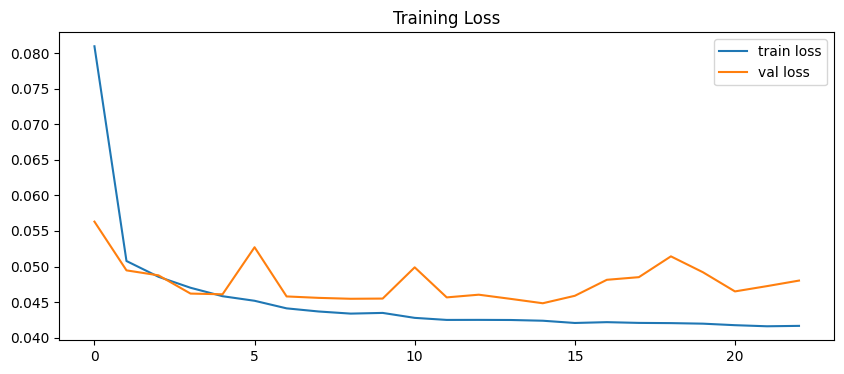

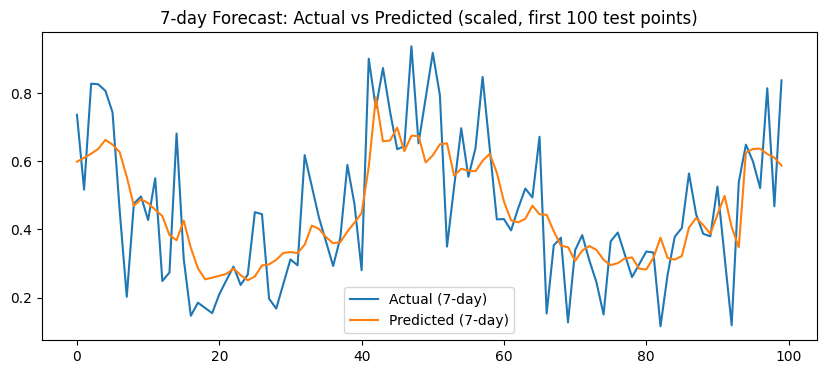

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

preds_7, preds_14 = model.predict(X_test)

mae_7 = mean_absolute_error(y7_test, preds_7)
r2_7 = r2_score(y7_test, preds_7)
mae_14 = mean_absolute_error(y14_test, preds_14)
r2_14 = r2_score(y14_test, preds_14)

print(f"7-day forecast  -> MAE (scaled): {mae_7:.4f} | R²: {r2_7:.4f}")
print(f"14-day forecast -> MAE (scaled): {mae_14:.4f} | R²: {r2_14:.4f}")

import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend(); plt.title('Training Loss'); plt.show()

plt.figure(figsize=(10,4))
plt.plot(y7_test[:100], label='Actual (7-day)')
plt.plot(preds_7[:100], label='Predicted (7-day)')
plt.legend(); plt.title('7-day Forecast: Actual vs Predicted (scaled, first 100 test points)')
plt.show()


## 9️⃣ Forecast Function (District-wise)
⚠️ Note: প্রতিটা district-এর নিজস্ব scaler আছে (কারণ case-count-এর মাত্রা district ভেদে ভিন্ন), তাই district অনুযায়ী সঠিক scaler ব্যবহার করতে হবে।


In [10]:
def forecast_district(district_name, weekly_filled=weekly_filled, lookback=LOOKBACK):
    if district_name not in scalers:
        return {"error": f"'{district_name}' not found or insufficient history."}

    group = weekly_filled[weekly_filled['district']==district_name].sort_values('week')
    if len(group) < lookback:
        return {"error": "Not enough historical weeks for this district."}

    last_window = group[feature_cols].values[-lookback:]
    scaler = scalers[district_name]
    scaled_window = scaler.transform(last_window)
    scaled_window = scaled_window.reshape(1, lookback, len(feature_cols))

    pred_7, pred_14 = model.predict(scaled_window, verbose=0)

    # inverse transform (only weekly_cases column, so pad with zeros for other features)
    def inverse_cases(scaled_val):
        dummy = np.zeros((1, len(feature_cols)))
        dummy[0,0] = scaled_val
        return scaler.inverse_transform(dummy)[0,0]

    return {
        'district': district_name,
        'forecast_next_7_days_cases': round(float(inverse_cases(pred_7[0][0])), 1),
        'forecast_next_14_days_cases': round(float(inverse_cases(pred_14[0][0])), 1)
    }

# Example
print(forecast_district(weekly_filled['district'].iloc[0]))


{'district': 'Bagerhat', 'forecast_next_7_days_cases': 117.2, 'forecast_next_14_days_cases': 117.1}


## 🔟 Save Model + Scalers

In [11]:
import joblib
import os

SAVE_DIR = '/content/drive/MyDrive/FloodShieldAI/models'
os.makedirs(SAVE_DIR, exist_ok=True)

model.save(f'{SAVE_DIR}/timeseries_lstm_model.keras')
joblib.dump(scalers, f'{SAVE_DIR}/timeseries_scalers.pkl')
joblib.dump(feature_cols, f'{SAVE_DIR}/timeseries_feature_cols.pkl')
joblib.dump(LOOKBACK, f'{SAVE_DIR}/timeseries_lookback.pkl')

print(f"✅ Saved to: {SAVE_DIR}")


✅ Saved to: /content/drive/MyDrive/FloodShieldAI/models


---
## ✅ পরের ধাপ
এই forecast (`forecast_district()`) dashboard-এ "Prediction History" ও "Next 7/14 Days Outlook" chart-এ ব্যবহার হবে।

**সৎ note:** এটা synthetic dataset-এর উপর ভিত্তি করে বানানো — real deployment-এর আগে প্রকৃত DGHS surveillance data দিয়ে validate করা উচিত।
